# MachineEar — 01 | Prétraitement général Fan + Pump

Adaptation du notebook initial : mêmes **52 caractéristiques acoustiques** (20 MFCC × moyenne/écart-type + 6 descripteurs × moyenne/écart-type), `duration_sec`, `file_path` et `label`. Ajout de `machine_type`, `machine_id` et `noise_level` pour travailler sur 8 machines. Aucune modification des WAV.

Exécuter les cellules dans l’ordre depuis VS Code, noyau `.venv`. Le traitement peut prendre du temps ; chaque CSV par machine est réutilisé au prochain lancement si `FORCE_REPROCESS=False`.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUTPUT_DIR = ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MACHINE_TYPES = ("fan", "pump")
MACHINE_IDS = ("id_00", "id_02", "id_04", "id_06")
NOISE_LEVEL = "0_dB"  # Adapter si les dossiers portent un autre niveau de bruit
FORCE_REPROCESS = False  # True pour recalculer même si les CSV existent
SHOW_SPECTROGRAMS = True
SAMPLE_RATE = 16000
print("Racine :", ROOT)


Racine : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar


c:\Users\0503506P\Downloads\MachineEar_VSCode\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Localiser les huit machines

Accepte les deux organisations courantes : `data/0_dB_fan/id_00/normal` et `data/fan/id_00/normal` (idem pour `pump`). Les dossiers absents sont signalés : **aucun résultat n’est inventé**.

In [2]:
def find_machine_dir(machine_type, machine_id):
    candidates = [
        ROOT / "data" / f"{NOISE_LEVEL}_{machine_type}" / machine_id,
        ROOT / "data" / machine_type / machine_id,
        ROOT / "data" / machine_type / NOISE_LEVEL / machine_id,
    ]
    return next((p for p in candidates if p.is_dir()), None)

machines = []
for machine_type in MACHINE_TYPES:
    for machine_id in MACHINE_IDS:
        folder = find_machine_dir(machine_type, machine_id)
        files = sorted(folder.rglob("*.wav")) if folder else []
        machines.append({"machine_type": machine_type, "machine_id": machine_id,
                         "folder": folder, "files": files, "wav_count": len(files)})
summary = pd.DataFrame([{k: v for k, v in item.items() if k != "files"} for item in machines])
display(summary)
if not any(m["files"] for m in machines):
    raise FileNotFoundError("Aucun WAV trouvé. Vérifier ROOT, NOISE_LEVEL et les dossiers data.")
print("Machines trouvées :", sum(bool(m["files"]) for m in machines), "/ 8")


,machine_type,machine_id,folder,wav_count
0,fan,id_00,C:\Users\0503506P\Downloads\MachineEar_VSCode\...,1418
1,fan,id_02,C:\Users\0503506P\Downloads\MachineEar_VSCode\...,1375
2,fan,id_04,C:\Users\0503506P\Downloads\MachineEar_VSCode\...,1381
3,fan,id_06,C:\Users\0503506P\Downloads\MachineEar_VSCode\...,1376
4,pump,id_00,C:\Users\0503506P\Downloads\MachineEar_VSCode\...,1149
5,pump,id_02,C:\Users\0503506P\Downloads\MachineEar_VSCode\...,1116
6,pump,id_04,C:\Users\0503506P\Downloads\MachineEar_VSCode\...,802
7,pump,id_06,C:\Users\0503506P\Downloads\MachineEar_VSCode\...,1138


Machines trouvées : 8 / 8


## 2. Afficher seulement trois spectrogrammes

L'affichage est un aperçu pédagogique, pas une visualisation de tous les audios.

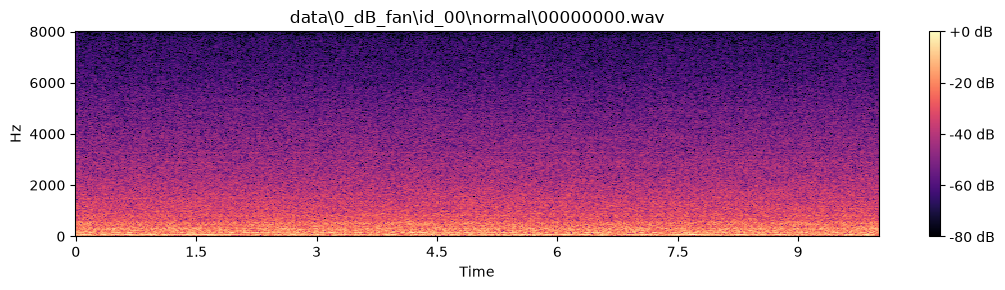

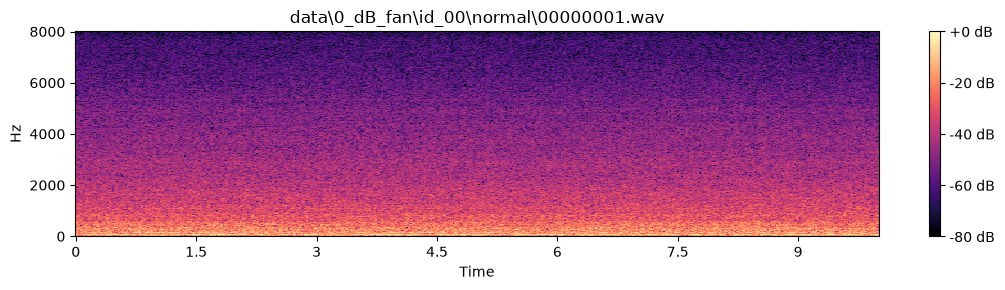

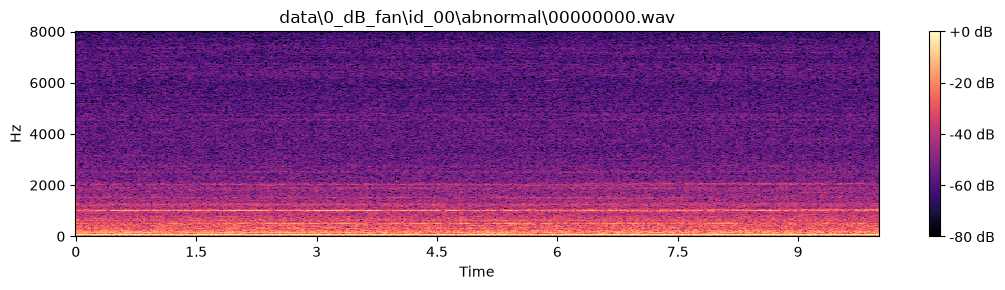

In [3]:
if SHOW_SPECTROGRAMS:
    available = [f for m in machines for f in m["files"]]
    normal_examples = [f for f in available if "normal" in f.parts and "abnormal" not in f.parts]
    abnormal_examples = [f for f in available if "abnormal" in f.parts]
    examples = (normal_examples[:2] + abnormal_examples[:1]) if normal_examples and abnormal_examples else available[:3]
    for file in examples:
        y, sr = librosa.load(file, sr=SAMPLE_RATE, mono=True)
        spec = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=1024, hop_length=256)), ref=np.max)
        plt.figure(figsize=(11, 3))
        librosa.display.specshow(spec, sr=sr, hop_length=256, x_axis="time", y_axis="linear", cmap="magma")
        plt.colorbar(format="%+2.0f dB")
        plt.title(str(file.relative_to(ROOT)))
        plt.tight_layout()
        plt.show()


## 3. Extraction des caractéristiques

Conserve **exactement les mêmes paramètres** que ton premier notebook pour permettre la comparaison. `label=0` signifie normal, `label=1` anormal. Les fichiers dont l'étiquette est inconnue sont ignorés et signalés.

In [4]:
def extract_features(file, machine_type, machine_id):
    y, sr = librosa.load(file, sr=SAMPLE_RATE, mono=True)
    if y.size == 0:
        raise ValueError("Audio vide")
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    features = {"file_path": str(file.relative_to(ROOT)), "duration_sec": len(y) / sr}
    for i, values in enumerate(mfcc, start=1):
        features[f"mfcc_{i:02d}_mean"] = float(np.mean(values))
        features[f"mfcc_{i:02d}_std"] = float(np.std(values))
    for name, arr in {
        "rms": librosa.feature.rms(y=y),
        "zcr": librosa.feature.zero_crossing_rate(y),
        "centroid": librosa.feature.spectral_centroid(y=y, sr=sr),
        "bandwidth": librosa.feature.spectral_bandwidth(y=y, sr=sr),
        "rolloff": librosa.feature.spectral_rolloff(y=y, sr=sr),
        "flatness": librosa.feature.spectral_flatness(y=y),
    }.items():
        features[f"{name}_mean"] = float(np.mean(arr))
        features[f"{name}_std"] = float(np.std(arr))
    parts = file.relative_to(ROOT).parts
    if "abnormal" in parts:
        label = 1
    elif "normal" in parts:
        label = 0
    else:
        raise ValueError("Dossier normal/abnormal absent du chemin")
    features.update({"label": label, "machine_type": machine_type,
                     "machine_id": machine_id, "noise_level": NOISE_LEVEL})
    return features


## 4. Traiter les huit machines et enregistrer les CSV

Chaque machine produit un CSV indépendant ; les fichiers sont ensuite regroupés dans `fan_pump_all_features.csv`. Pour éviter de recalculer inutilement, les CSV existants sont chargés si leur schéma est compatible et que `FORCE_REPROCESS=False`. Si les WAV ont changé, mettre `FORCE_REPROCESS=True`.

In [5]:
all_frames, errors = [], []
expected_columns = {"file_path", "duration_sec", "label", "machine_type", "machine_id", "noise_level", "mfcc_01_mean", "flatness_std"}
for machine in machines:
    machine_type, machine_id, files = machine["machine_type"], machine["machine_id"], machine["files"]
    if not files:
        print(f"IGNORÉ (aucun WAV) : {machine_type}/{machine_id}")
        continue
    output = OUTPUT_DIR / f"{NOISE_LEVEL}_{machine_type}_{machine_id}_features.csv"
    if output.exists() and not FORCE_REPROCESS:
        cached = pd.read_csv(output)
        cached_paths = set(cached["file_path"].astype(str)) if "file_path" in cached else set()
        current_paths = {str(f.relative_to(ROOT)) for f in files}
        if expected_columns.issubset(cached.columns) and cached_paths == current_paths:
            print(f"Cache réutilisé : {output.name} ({len(cached)} lignes)")
            all_frames.append(cached)
            continue
        print(f"Cache incomplet ou incompatible, recalcul : {output.name}")
    rows = []
    for file in tqdm(files, desc=f"{machine_type}/{machine_id}"):
        try:
            rows.append(extract_features(file, machine_type, machine_id))
        except Exception as exc:
            errors.append({"file_path": str(file), "error": str(exc)})
    if rows:
        frame = pd.DataFrame(rows)
        frame.to_csv(output, index=False)
        all_frames.append(frame)
        print(f"Enregistré : {output.name} — {len(frame)} lignes")

if not all_frames:
    raise RuntimeError("Aucun fichier audio valide n'a pu être traité")
df = pd.concat(all_frames, ignore_index=True)
combined_path = OUTPUT_DIR / "fan_pump_all_features.csv"
df.to_csv(combined_path, index=False)
print(f"\nCSV général : {combined_path} — {df.shape[0]} lignes, {df.shape[1]} colonnes")
print("Erreurs :", len(errors))
if errors:
    error_path = OUTPUT_DIR / "audio_extraction_errors.csv"
    pd.DataFrame(errors).to_csv(error_path, index=False)
    display(pd.DataFrame(errors).head())
display(df.head())


fan/id_00: 100%|██████████| 1418/1418 [03:55<00:00,  6.01it/s]


Enregistré : 0_dB_fan_id_00_features.csv — 1418 lignes


fan/id_02: 100%|██████████| 1375/1375 [03:14<00:00,  7.08it/s]


Enregistré : 0_dB_fan_id_02_features.csv — 1375 lignes


fan/id_04: 100%|██████████| 1381/1381 [03:13<00:00,  7.14it/s]


...

pump/id_04: 100%|██████████| 802/802 [01:55<00:00,  6.94it/s]


Enregistré : 0_dB_pump_id_04_features.csv — 802 lignes


pump/id_06: 100%|██████████| 1138/1138 [02:49<00:00,  6.69it/s]


Enregistré : 0_dB_pump_id_06_features.csv — 1138 lignes

CSV général : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\data\processed\fan_pump_all_features.csv — 9755 lignes, 58 colonnes
Erreurs : 0


,file_path,duration_sec,mfcc_01_mean,mfcc_01_std,mfcc_02_mean,mfcc_02_std,mfcc_03_mean,mfcc_03_std,mfcc_04_mean,mfcc_04_std,...,bandwidth_mean,bandwidth_std,rolloff_mean,rolloff_std,flatness_mean,flatness_std,label,machine_type,machine_id,noise_level
0,data\0_dB_fan\id_00\abnormal\00000000.wav,10.0,-396.144806,3.402323,135.755417,2.970131,20.228804,3.011735,8.463317,2.858978,...,1544.250499,40.589913,1750.299521,138.440346,0.003269,0.000824,1,fan,id_00,0_dB
1,data\0_dB_fan\id_00\abnormal\00000001.wav,10.0,-384.965607,4.134365,130.965836,3.116457,18.180664,2.755145,8.505290,2.902241,...,1583.041529,37.913310,1906.200080,144.761601,0.003485,0.000739,1,fan,id_00,0_dB
2,data\0_dB_fan\id_00\abnormal\00000002.wav,10.0,-391.158020,3.553493,125.811378,3.026743,27.886906,2.784920,14.952944,2.813266,...,1646.105570,44.674238,1994.608626,202.882425,0.003672,0.000877,1,fan,id_00,0_dB
3,data\0_dB_fan\id_00\abnormal\00000003.wav,10.0,-385.222290,4.044104,131.047226,3.088454,17.204878,3.255453,8.544799,3.055152,...,1570.191530,40.250307,1896.615415,144.310978,0.003400,0.000779,1,fan,id_00,0_dB
4,data\0_dB_fan\id_00\abnormal\00000004.wav,10.0,-389.398376,3.277032,146.362717,3.078448,-3.363282,2.994202,35.268394,2.809728,...,1276.630418,34.411200,1784.195288,115.346389,0.002431,0.000887,1,fan,id_00,0_dB


## 5. Contrôles qualité et répartition par machine

Le CSV général sert à l'exploration et à la comparaison. **Ne pas inclure** `file_path`, `machine_type`, `machine_id`, `noise_level`, `duration_sec` ou `label` parmi les caractéristiques du modèle sans justification. Les découpages par machine doivent être définis avant normalisation, sélection de variables et entraînement.

In [6]:
print("Dimensions :", df.shape)
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("Chemins dupliqués :", int(df["file_path"].duplicated().sum()))
feature_cols = [c for c in df.columns if c.startswith("mfcc_") or c.endswith(("_mean", "_std"))]
print("Caractéristiques acoustiques :", len(feature_cols))
print("Valeurs non finies :", int((~np.isfinite(df[feature_cols].to_numpy(dtype=float))).sum()))
print("\nRépartition par type, identifiant et étiquette :")
display(pd.crosstab([df["machine_type"], df["machine_id"]], df["label"], margins=True))
print("\nDurées :")
display(df["duration_sec"].describe())


Dimensions : (9755, 58)
Valeurs manquantes : 0
Chemins dupliqués : 0
Caractéristiques acoustiques : 52
Valeurs non finies : 0

Répartition par type, identifiant et étiquette :


label                       0     1   All
machine_type machine_id                  
fan          id_00       1011   407  1418
             id_02       1016   359  1375
             id_04       1033   348  1381
             id_06       1015   361  1376
pump         id_00       1006   143  1149
             id_02       1005   111  1116
             id_04        702   100   802
             id_06       1036   102  1138
All                      7824  1931  9755


Durées :


count    9755.0
mean       10.0
std         0.0
min        10.0
25%        10.0
50%        10.0
75%        10.0
max        10.0
Name: duration_sec, dtype: float64

## Suite du projet

Le notebook `03_model_comparison.ipynb` pourra charger `data/processed/fan_pump_all_features.csv`, comparer les modèles sur un même protocole, puis réaliser une validation **leave-one-machine-id-out** (entraînement sur certains identifiants, test sur un autre). Un modèle déjà entraîné sur `fan/id_00` doit être testé sur les autres identifiants **sans réentraînement ni recalibrage du seuil sur le test**. Attention : les performances obtenues sur une machine non vue peuvent être sensiblement inférieures.